# Lab 3: Clustering

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to code the agglomerative single Linkage clustering algorithm, and compare it with other methods

Please put **"ML - MDS - TD3"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L3_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.cluster as cluster # all clustering techniques except hdbscan
%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}

We will have two toy datasets to try the different methods:

There are a lot of clustering algorithms to choose from the `sklearn` library. So what clustering algorithms should you be using? It depends.

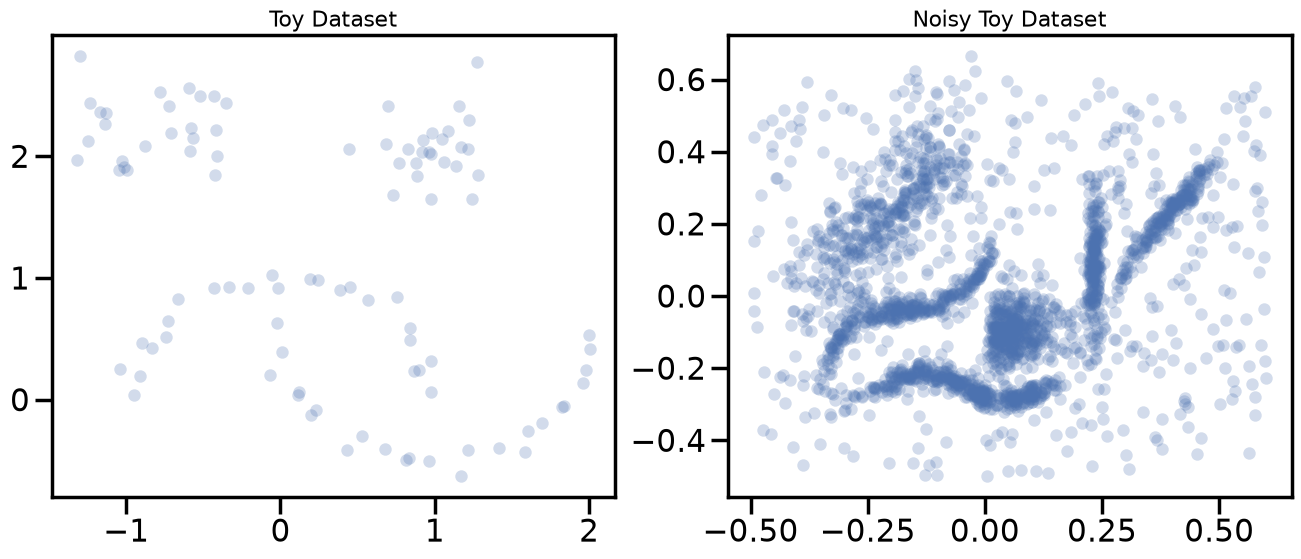

In [2]:
import sklearn.datasets as data
moons, _ = data.make_moons(n_samples=50, noise=0.05)
blobs, _ = data.make_blobs(n_samples=50, centers=[(-0.75,2.25), (1.0, 2.0)], cluster_std=0.25)
test_data_0 = np.vstack([moons, blobs])

test_data_1 = np.load('clusterable_data.npy')

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c='b', **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], color='b', **plot_kwds)
ax[1].set_title('Noisy Toy Dataset', size=16)

plt.show();

## K-means

K-Means is the 'go-to' clustering algorithm for many simply because it is fast, easy to understand, and available everywhere (there's an implementation in almost any statistical or machine learning tool you care to use). However, K-Means has a few problems caused by its simplicity. 

We try the `sklearn` implementation in our toy datasets:

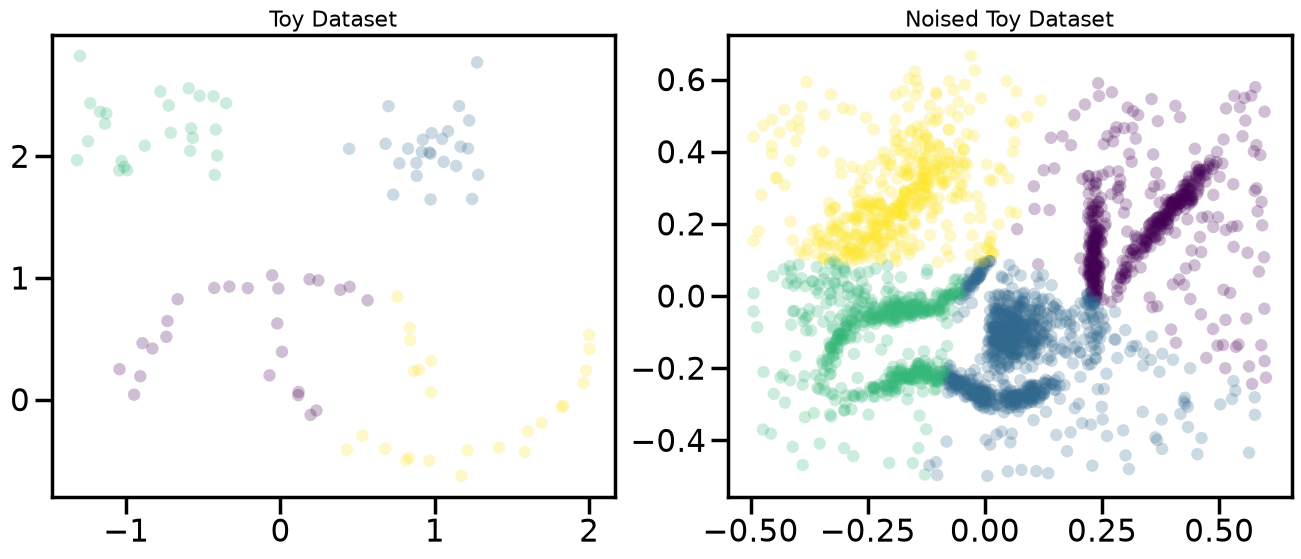

In [3]:
from sklearn.cluster import KMeans
kmeans_0 = KMeans(n_clusters=4, max_iter=200).fit(test_data_0)
kmeans_1 = KMeans(n_clusters=4, max_iter=200).fit(test_data_1)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].scatter(test_data_0.T[0], test_data_0.T[1], c=kmeans_0.labels_ , **plot_kwds)
ax[0].set_title('Toy Dataset', size=16)

ax[1].scatter(test_data_1.T[0], test_data_1.T[1], c=kmeans_1.labels_, **plot_kwds)
ax[1].set_title('Noised Toy Dataset', size=16)


plt.show();

## Agglomerative Single Linkage clustering

Agglomerative clustering is a suite of algorithms all based on the same idea. The fundamental idea is that you start with each point in it's own cluster and then, for each cluster, use some criterion to choose another cluster to merge with. Do this repeatedly until you have only one cluster and you get get a hierarchy, or binary tree, of clusters branching down to the last layer which has a leaf for each point in the dataset. The most basic version of this, single linkage, chooses the closest cluster to merge, and hence the tree can be ranked by distance as to when clusters merged/split.

**Code your own Agglomerative Single Linkage clustering algorithm**!:

- Fill in the class 
- During the process, keep track of the cluster merges by saving a (num_samples-1,4) np.array being a linkage matrix in scypy format (to use their function to plot dendrogram: `scipy.cluster.hierarchy.dendrogram`). check documentation.

In [4]:
from scipy.spatial import distance

In [5]:
import scipy


class my_SingleLinkageAgglomerativeClustering():
    
    def __init__(self, n_clusters=3):
        '''
        Attributes:
        
        n_clusters: integer
            number of clusters to return 
        linkage_matrix_: (n-1, 4) np.array
            in the same format as linkage (check documentation for scipy.cluster.hierarchy.linkage)  
        hierarchy_: list of np.array
            each array corresponds to label assigment
            at each level (number of clusters)
            hierarchy_[0]=np.array(list(range(n)))
        labels_: integer np.array
            label assignement
        '''
        self.n_clusters_ = n_clusters
        self.linkage_matrix_ = None
        self.labels_ = None
        self.hierarchy_ = None
        
    def fit(self, X):
        """ Create a hierarchy of clusters
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Note:
        -----
        Updates self.linkage_matrix, self.labels and self.hierarchy
        """

        #TODO

        # Compute the distance matrix using from scipy.spatial import distance 
        
        # HINT:
        # Modify the distance matrix (ex: add row/column for new clusters and remove/put zero in old row/colums)
        # or you can use a minimum spanning tree and add merge in increasing order
        # or something else !
        
        # keep track of merges in linkage_matrix_ and labels in hierarchy_
        
        # update labels_ from the hierarchy level selected by n_clusters_ 
        clusters =  [[k] for k in range(X.shape[0]) ] 
        self.linkage_matrix_ = np.zeros((X.shape[0]-1, 4))
        self.hierarchy_ = []
        self.hierarchy_.append(np.array(list(range(X.shape[0]))))
        n = X.shape[0]
        distance_matrix = distance.cdist(X,X) 
        np.fill_diagonal(distance_matrix, np.inf)
        ids = list(range(n))
        n_iter = 0
        while len(clusters) > 1:
            n_iter +=1
            i, j = np.unravel_index(np.argmin(distance_matrix), distance_matrix.shape)
            i,j = sorted((i,j))
            self.linkage_matrix_[n_iter-1] = [ids[i], ids[j], distance_matrix[i, j],
                                  len(clusters[i]) + len(clusters[j])]
           
            id = [i,j] 
            new_dist = np.minimum(distance_matrix[i], distance_matrix[j])
            new_dist = np.delete(new_dist, [i, j])
    
            distance_matrix = np.delete(distance_matrix, id, axis = 0)
            distance_matrix = np.delete(distance_matrix, id, axis = 1)

            distance_matrix = np.vstack([distance_matrix, new_dist])
            distance_matrix = np.hstack([distance_matrix, np.append(new_dist, np.inf)[:, None]])
           
            new_cluster = clusters[i] + clusters[j]
            for k in [j,i]:
                del clusters[k]
                del ids[k]
            clusters.append(new_cluster)
            ids.append(n + n_iter -1) 
            labels = np.empty(n, dtype=int)
            for c, cid in zip(clusters, ids):
                labels[c] = cid
            self.hierarchy_.append(labels)

        # now select n_clusters : 
        selected_clusters = self.hierarchy_[n - self.n_clusters_]
        _, self.labels_ = np.unique(selected_clusters, return_inverse=True)
        
    def plot_dendrogram(self):
        '''Use self.linkage_matrix_ in `scipy.cluster.hierarchy.dendrogram` 
        to plot the dendrogram of the hierarchical structure
        '''
        scipy.cluster.hierarchy.dendrogram(self.linkage_matrix_)
        
        # 

Apply the method to our toy datasets

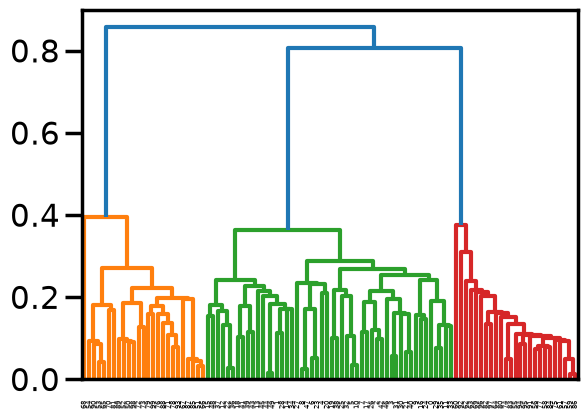

In [6]:
from scipy.spatial import distance 
from scipy.cluster.hierarchy import dendrogram

agg = my_SingleLinkageAgglomerativeClustering()
agg.fit(test_data_0)
agg.plot_dendrogram()

Text(0.5, 1.0, 'Agglomerative Clustering with Single Linkage')

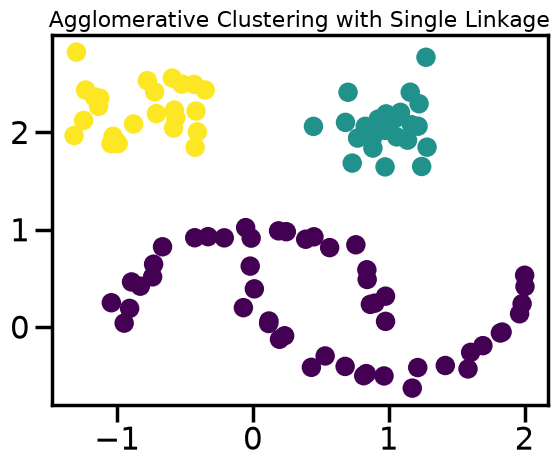

In [7]:
plt.scatter(test_data_0[:, 0], test_data_0[:, 1], c=agg.labels_, marker='o')
plt.title('Agglomerative Clustering with Single Linkage', size=16)

Try the different linkage methods implemented in `sklearn`  and comment

{'icoord': [[35.0, 35.0, 45.0, 45.0],
  [25.0, 25.0, 40.0, 40.0],
  [15.0, 15.0, 32.5, 32.5],
  [55.0, 55.0, 65.0, 65.0],
  [23.75, 23.75, 60.0, 60.0],
  [95.0, 95.0, 105.0, 105.0],
  [85.0, 85.0, 100.0, 100.0],
  [75.0, 75.0, 92.5, 92.5],
  [115.0, 115.0, 125.0, 125.0],
  [83.75, 83.75, 120.0, 120.0],
  [135.0, 135.0, 145.0, 145.0],
  [185.0, 185.0, 195.0, 195.0],
  [175.0, 175.0, 190.0, 190.0],
  [165.0, 165.0, 182.5, 182.5],
  [155.0, 155.0, 173.75, 173.75],
  [140.0, 140.0, 164.375, 164.375],
  [235.0, 235.0, 245.0, 245.0],
  [225.0, 225.0, 240.0, 240.0],
  [215.0, 215.0, 232.5, 232.5],
  [205.0, 205.0, 223.75, 223.75],
  [152.1875, 152.1875, 214.375, 214.375],
  [101.875, 101.875, 183.28125, 183.28125],
  [41.875, 41.875, 142.578125, 142.578125],
  [5.0, 5.0, 92.2265625, 92.2265625],
  [255.0, 255.0, 265.0, 265.0],
  [295.0, 295.0, 305.0, 305.0],
  [285.0, 285.0, 300.0, 300.0],
  [275.0, 275.0, 292.5, 292.5],
  [260.0, 260.0, 283.75, 283.75],
  [315.0, 315.0, 325.0, 325.0],
  [335

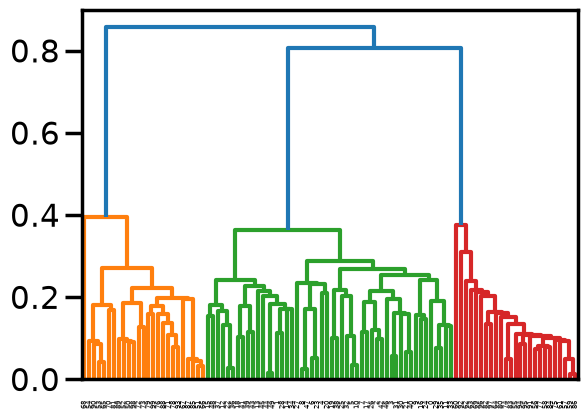

In [8]:
from scipy.cluster.hierarchy import linkage
linkage_matrix = linkage(test_data_0, method='single')
dendrogram(linkage_matrix)



## DBSCAN

DBSCAN is a density based algorithm -- it assumes clusters for dense regions. It is also the first actual clustering algorithm we've looked at: it doesn't require that every point be assigned to a cluster and hence doesn't partition the data, but instead extracts the 'dense' clusters and leaves sparse background classified as 'noise'. In practice DBSCAN is related to agglomerative clustering. As a first step DBSCAN transforms the space according to the density of the data: points in dense regions are left alone, while points in sparse regions are moved further away. Applying single linkage clustering to the transformed space results in a dendrogram, which we cut according to a distance parameter (called epsilon or `eps` in many implementations) to get clusters. Importantly any singleton clusters at that cut level are deemed to be 'noise' and left unclustered. 

Apply it to the test_data, how do you tune the parameters?

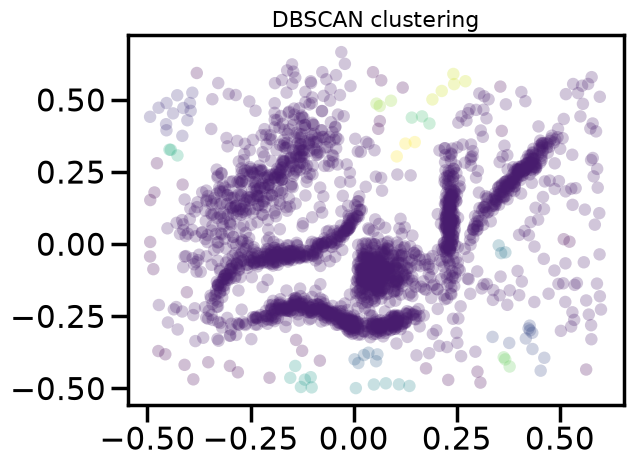

In [31]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.05, min_samples=3).fit(test_data_1)
dbscan.labels_
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}
plt.scatter(test_data_1.T[0], test_data_1.T[1], c=dbscan.labels_, **plot_kwds)
plt.title('DBSCAN clustering', size=16)
plt.show()

## HDBSCAN

HDBSCAN is a recent algorithm developed by some of the same people who write the original DBSCAN paper. Their goal was to allow varying density clusters. The algorithm starts off much the same as DBSCAN: we transform the space according to density, exactly as DBSCAN does, and perform single linkage clustering on the transformed space. Instead of taking an epsilon value as a cut level for the dendrogram however, a different approach is taken: the dendrogram is condensed by viewing splits that result in a small number of points splitting off as points 'falling out of a cluster'. This results in a smaller tree with fewer clusters that 'lose points'. That tree can then be used to select the most stable or persistent clusters. This process allows the tree to be cut at varying height, picking our varying density clusters based on cluster stability.

/home/aubincharley/Documents/Cours/Experiments/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


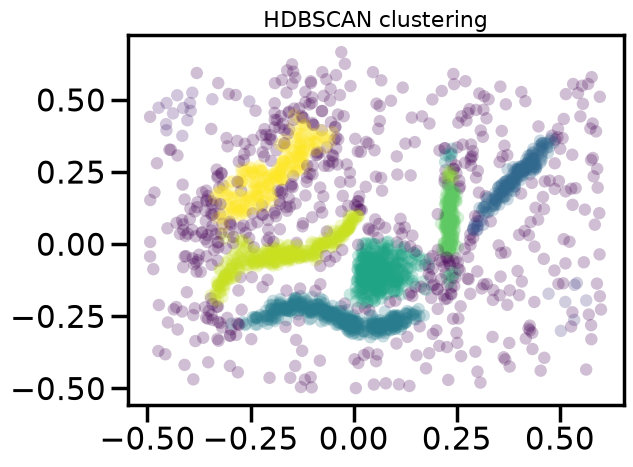

In [41]:
from sklearn.cluster import HDBSCAN
hdbscan = HDBSCAN(min_samples=10, min_cluster_size=5).fit(test_data_1)
hdbscan.labels_
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}
plt.scatter(test_data_1.T[0], test_data_1.T[1], c=hdbscan.labels_, **plot_kwds)
plt.title('HDBSCAN clustering', size=16)
plt.show()
    

## Apply the algorithms to the following images and comment the results

### NASA Curiosity Picture

- Look at following NASA photo taken by a robot in mars:


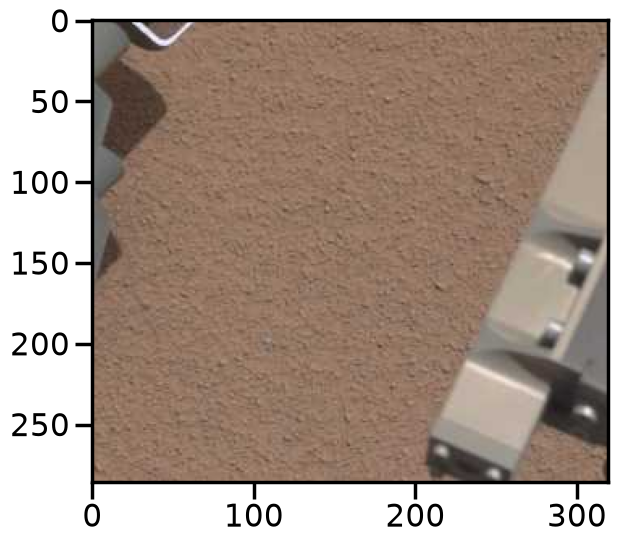

In [ ]:
from PIL import Image

Im_1  = Image.open('im_nasa_reduced.jpg')

fig = plt.figure(figsize=(8, 6))
plt.imshow(Im_1)
plt.show()

- Transform the image to an intensity (I) and saturation (S) representation, it helps to distinguish bright and textures.

$$I=\frac{R+G+B}{3}$$
$$S=1-I\times min(R, G, B)$$

In [21]:
# https://pages.hmc.edu/ruye/e161/lectures/ColorProcessing/node2.html // right formula for saturation is S = 1 - 1/I * np.min(Im_1, axis=2)
print(np.array(Im_1).shape)
I = np.mean(Im_1, axis=2)
S = 1 - 1/(I) * np.min(Im_1, axis=2)
print(I.shape, S.flatten().shape)


(286, 320, 3)
(286, 320) (91520,)


- Apply the seen algorithms to segment the image in the Intensity-Saturation representation, comment the results and check if you find something on mars' surface. Be careful with hdbscan and memory errors for some parameters choice (use algorithm='boruvka_kdtree').

In [55]:
#apply boruvka kdtree algorithm to cluster the image
import hdbscan 
model = hdbscan.HDBSCAN(min_cluster_size=30,algorithm="boruvka_kdtree")
flattened_S = S.flatten().reshape(-1, 1)
print(flattened_S.shape)
IS = np.hstack([I.flatten().reshape(-1,1)/255, flattened_S])
print(IS.shape)
model.fit(IS)


(91520, 1)
(91520, 2)


,min_cluster_size,30
,algorithm,'boruvka_kdtree'
,min_samples,None
,cluster_selection_epsilon,0.0
,cluster_selection_persistence,0.0
,max_cluster_size,0
,metric,'euclidean'
,alpha,1.0
,p,None
,leaf_size,40
,memory,Memory(location=None)


(286, 320)


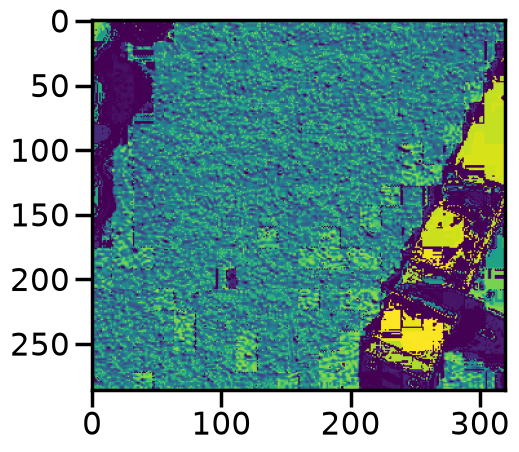

In [56]:
print(model.labels_.reshape(S.shape).shape)
plt.imshow(model.labels_.reshape(S.shape))

### Color compression

One interesting application of clustering is in color compression within images. 
For example, imagine you have an image with millions of colors.
In most images, a large number of the colors will be unused, and many of the pixels in the image will have similar or even identical colors.

Get a simplified 10-colored version of the following image by applying k-means. Plot both images.

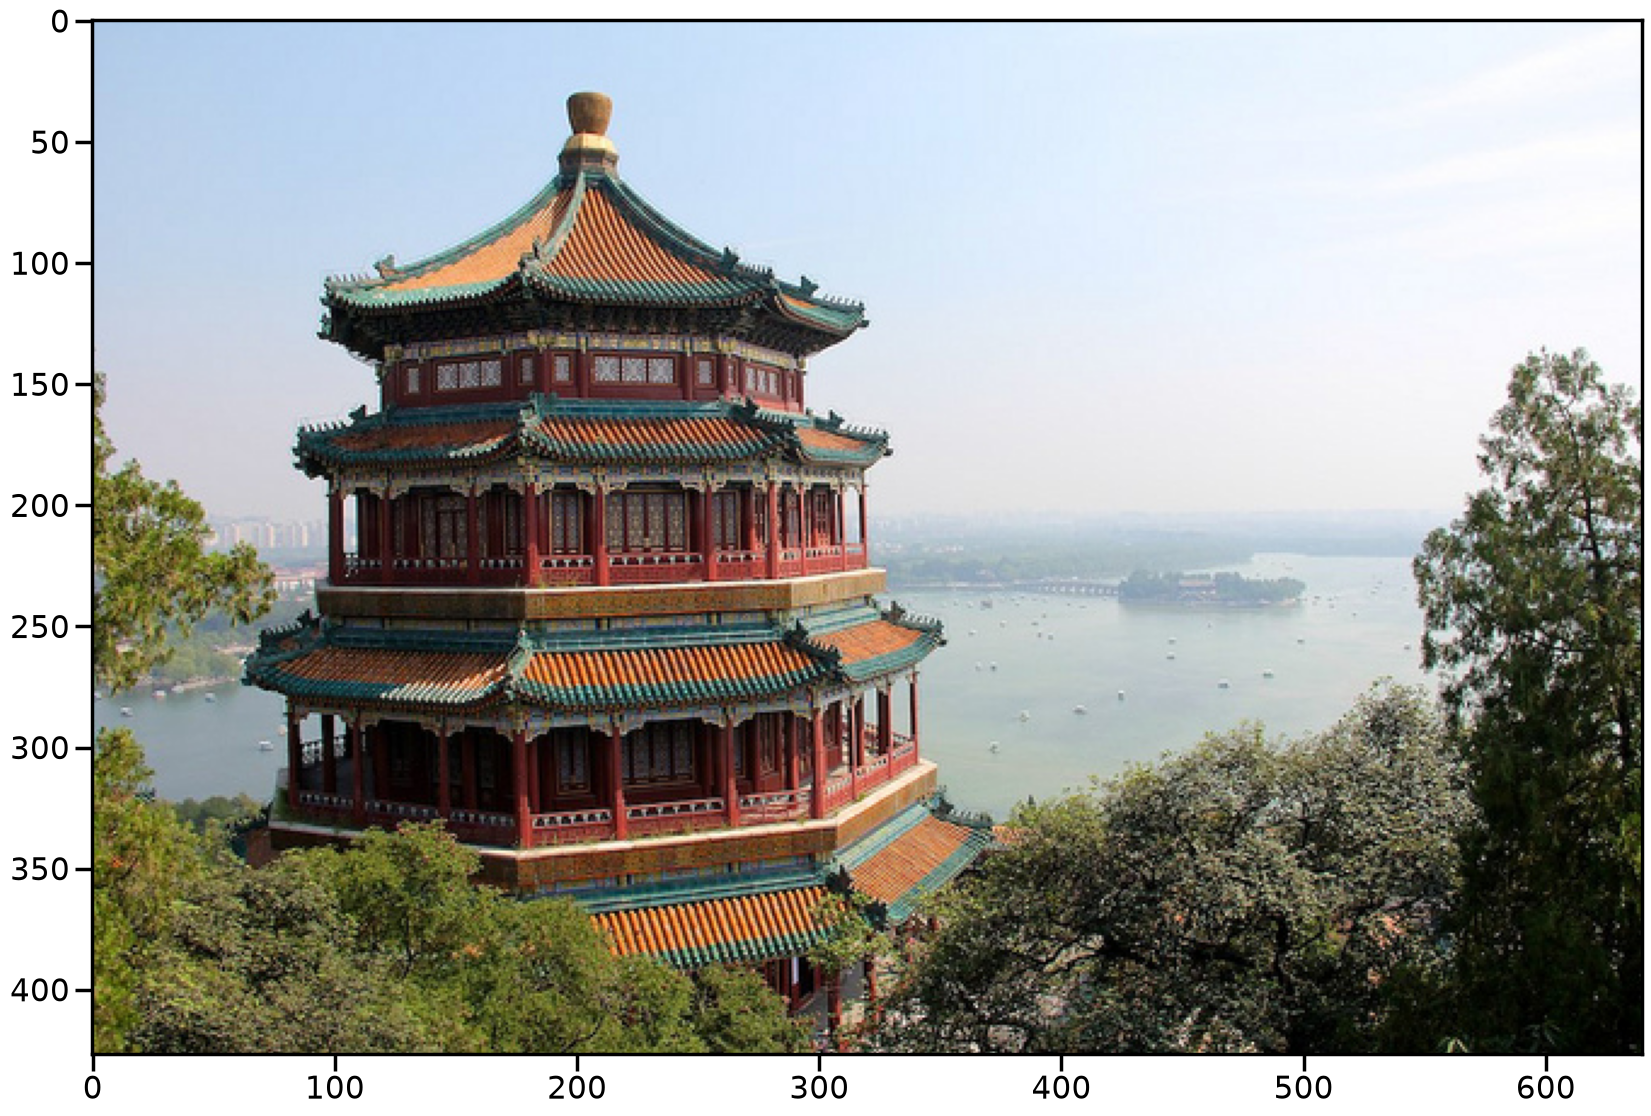

In [15]:
from sklearn.datasets import load_sample_image
china = load_sample_image("china.jpg")

fig = plt.figure(figsize=(20, 20))
plt.imshow(china);

10


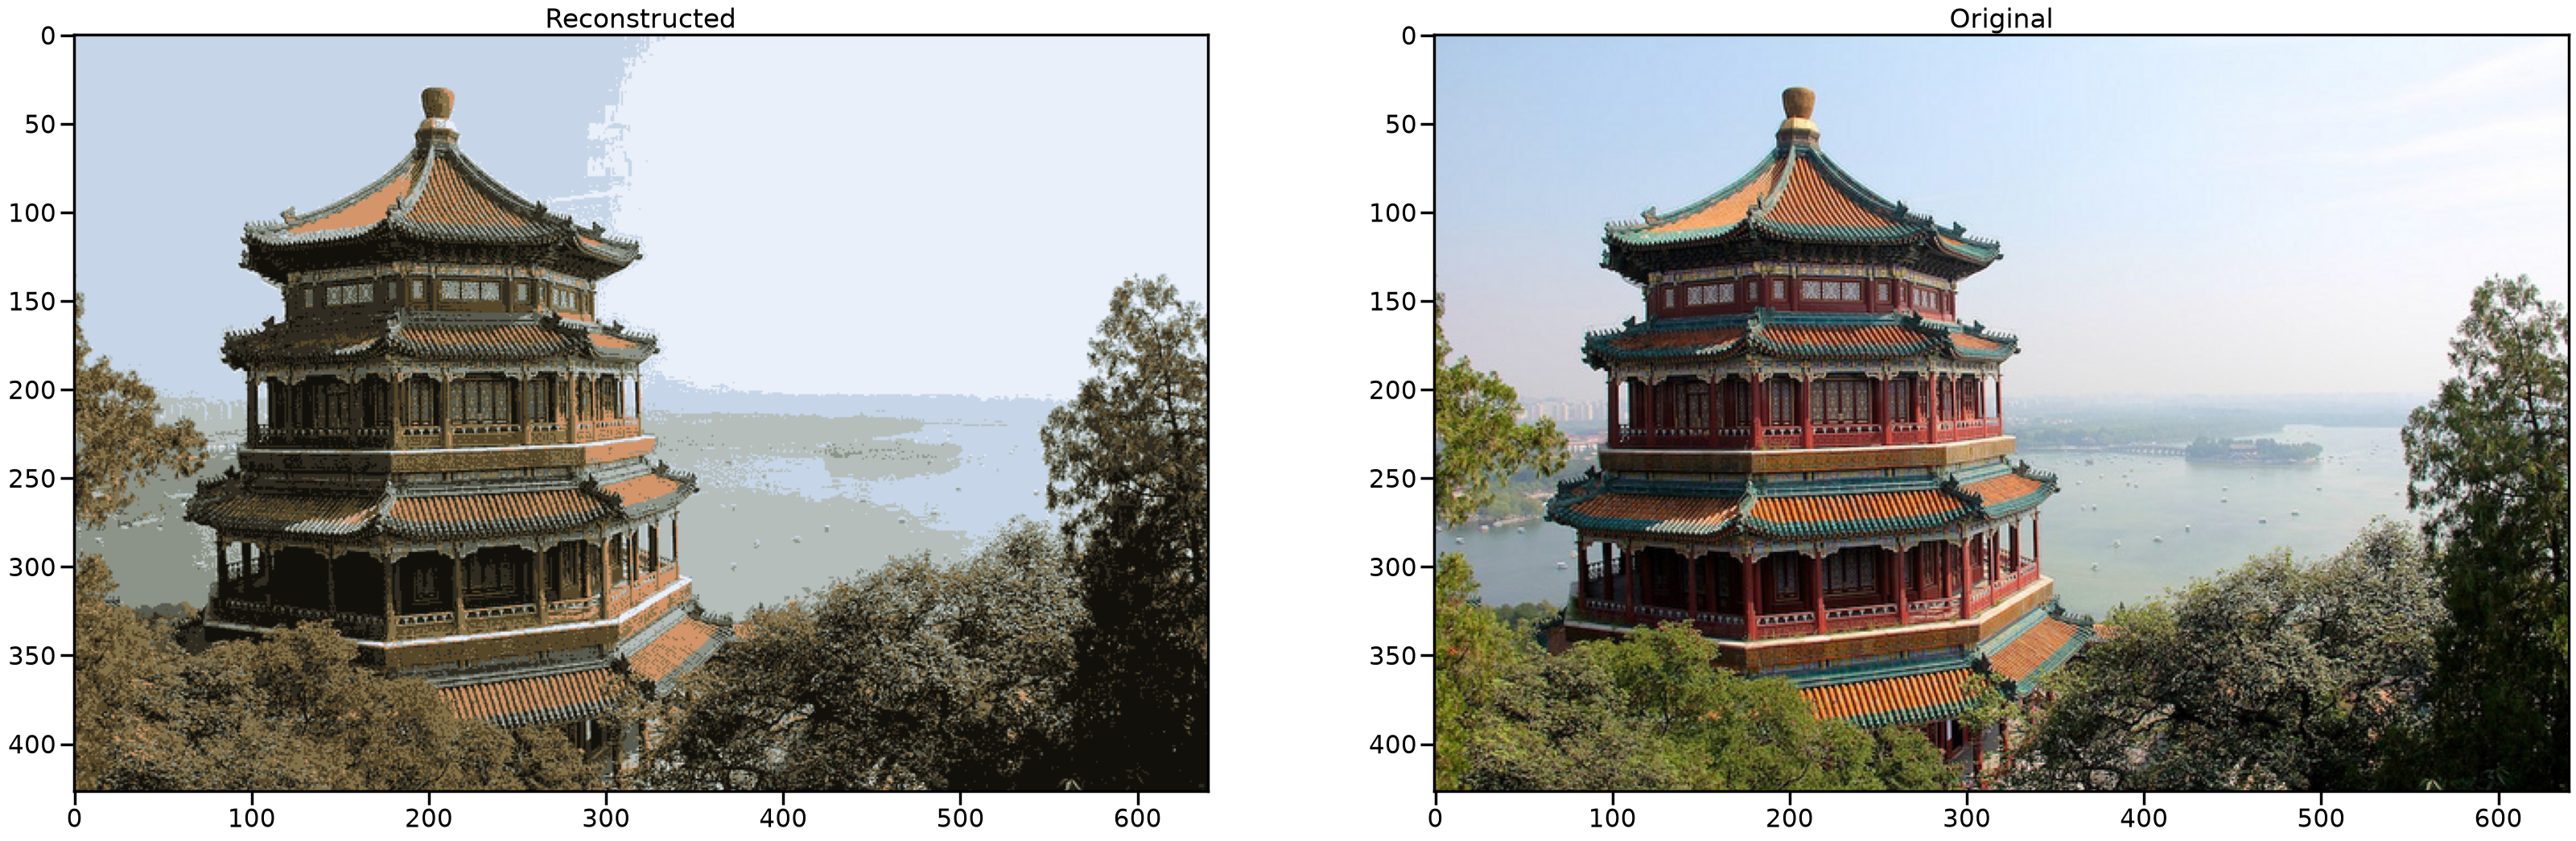

In [16]:
# TODO
model = KMeans(n_clusters=10)
model.fit(china.flatten().reshape(-1, 3))
reconstructed = model.labels_.reshape(china.shape[0], china.shape[1])
centroids = model.cluster_centers_.reshape(-1, 1, 3).astype(np.uint8)

reconstructed = np.array([centroids[label] for label in model.labels_]).reshape(china.shape)

print(len(centroids))
plt.figure(figsize=(40,20))
plt.subplot(1,2,1)
plt.title("Reconstructed")
plt.imshow(reconstructed)
plt.subplot(1,2,2)
plt.title("Original")
plt.imshow(china)
